## Mean field of a single population with N synaptic channels

#### Ilaria Carannante
mailto: ilariac@kth.se
###### KTH, Stockholm, Sweden
###### NeuroPSI, ICN, Saclay, France

In this notebook we run the mean field of a population of neurons with N synaptic channels (here 4), using the transfer function fitted in *TF_fitting_neuron_4_inputs.ipynb*. Each channel receives its own time-varying input rate, defined by a stimulation protocol (*config/input_config_4_channels.json*). The population rate follows

$$\tau_f \frac{d\nu}{dt} = TF(\nu_1(t), \dots, \nu_N(t)) - \nu$$

Adaptation is baked into the transfer function (fitted with $w_{ad} = 0$ on stationary rates), so there is no adaptation variable: the mean field is expected to match the steady-state rates, not the adaptation transients after each input step.

Optionally, the same protocol is simulated with the spiking neurons (N disconnected AdEx cells, same input scheme as the TF extraction) and the two population rates are compared.

In [1]:
#%matplotlib widget
import matplotlib.pyplot as plt

In [2]:
import sys
import os
import json

# Adding the project folder to sys.path
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))   # adjust if this notebook is deeper in the tree
sys.path.append(project_root)

In [3]:
from utils.Plots_helper import *
from ntmf.config import get_params_model_SI_general, adding_K_params_general, get_input_config
from ntmf.meanfield_nchannels import (load_TF_fit, driving_input_from_protocol, simulate_MF_single_pop,
                                      simulate_NN_single_pop, compare_MF_NN_single_pop)

In [4]:
# Setting file saving
figs = []
fig_path = os.path.join('figures')
isExist = os.path.exists(fig_path)
if not isExist:
   os.makedirs(fig_path)
   print('The directory "figures" is created.')

def save_figs(fig_path, name, figs):
    pdf_file_path = os.path.join(fig_path, name + '-figs.pdf')
    with PdfPages(pdf_file_path) as ofile:
        for fig in figs:
            ofile.savefig(fig) 

## Settings

In [5]:
neuron_model = 'neuron_4_inputs'
fig_name = f'MF_single_pop_{neuron_model}'

# Neuron model
data_folder = os.path.join(project_root, 'neuron_models', 'AdEx')
neuron_json = os.path.join(data_folder, neuron_model + '.json')
idx = 0

# Transfer-function fit: results file and the extraction metadata it was fitted on
fit_file = os.path.join(project_root, 'transfer_function', 'fitting', 'results', f'10_best_params_TF_{neuron_model}.json')
fit_rank = 0                      # 0 = best fit (lowest mean error)
tf_meta_file = os.path.join(project_root, 'transfer_function', 'data_extraction', 'simulations',
                            f'TF_{neuron_model}_delay_v1', f'TF_data_{neuron_model}_meta.json')
include_background = True         # must match the setting used in the fitting notebook

# Stimulation protocol
protocol_file = os.path.join(project_root, 'config', 'input_config_4_channels.json')

# Simulation
sim_duration = 6.0                # s
dt = 1e-4                         # s
tau_f = 0.01                      # s, population time constant (as for RS/FS)

# Comparison with spiking neurons (one Brian2 run of N_cell disconnected neurons)
run_spiking_comparison = True
N_cell = 50
bin_size = 0.05                   # s
t_window = (0.5, sim_duration)    # comparison window (skip the initial transient)

## Setting up the neuron model and the transfer function

In [6]:
params_SI = get_params_model_SI_general(json_file_name = neuron_json, idx = idx)

with open(tf_meta_file, 'r') as fh:
    tf_meta = json.load(fh)
params_SI = adding_K_params_general(neuron_params = params_SI,
                                    tf_meta = tf_meta,
                                    include_background = include_background)

alpha, poly_params, fit_entry = load_TF_fit(fit_file, rank = fit_rank)
if 'include_background' in fit_entry:
    assert fit_entry['include_background'] == include_background, 'include_background differs from the fit'
print(f'alpha = {alpha}, mean error = {fit_entry["mean_error"]:.3f}')
print(f'polynomial params = {poly_params}')

alpha = 0.679, mean error = 2.193
polynomial params = [-0.05206871  0.00766653  0.00293319  0.00014272  0.00015612  0.02191801
 -0.00655056  0.00169598  0.00174697  0.0128849 ]


In [7]:
ch_info = tf_channel_info(tf_meta)
for k, c in params_SI['channels'].items():
    print(f"{ch_info[k]['short']}: E = {1e3 * c['E']:g} mV, Q = {1e9 * c['Q']:g} nS, tau = {1e3 * c['tau']:g} ms, K = {c['K']:g}")

ch 1 (exc): E = 0 mV, Q = 1.5 nS, tau = 3 ms, K = 300
ch 2 (inh): E = -80 mV, Q = 5 nS, tau = 5 ms, K = 100
ch 3 (inh): E = -80 mV, Q = 1 nS, tau = 7 ms, K = 70
ch 4 (exc): E = 0 mV, Q = 2.5 nS, tau = 7 ms, K = 30


## Driving input from the stimulation protocol
Background plus stimulation windows, per channel. If the protocol's $K_s$ differs from the $K_s$ the TF was fitted with, the rates are rescaled by $K_{protocol} / K_{fit}$ (printed below if it happens).

In [8]:
protocol = get_input_config(json_file_name = protocol_file)
time = np.arange(0, sim_duration, dt)

driving_input = driving_input_from_protocol(input_config = protocol,
                                            time = time,
                                            params = params_SI,
                                            include_background = True)
for k, ch in protocol['channels'].items():
    print(f"ch {k}: background {ch['background_freq']} Hz, stimulations {ch['stimulations']}")

ch 1: background 1.0 Hz, stimulations [{'t_start': 1.0, 't_end': 2.0, 'freq': 12.0}]
ch 2: background 0.0 Hz, stimulations [{'t_start': 2.0, 't_end': 3.0, 'freq': 10.0}]
ch 3: background 0.0 Hz, stimulations [{'t_start': 4.0, 't_end': 5.0, 'freq': 10.0}]
ch 4: background 0.0 Hz, stimulations [{'t_start': 3.0, 't_end': 4.0, 'freq': 10.0}]


## Running the mean field

In [9]:
mf = simulate_MF_single_pop(time = time,
                            driving_input = driving_input,
                            params = params_SI,
                            poly_params = poly_params,
                            alpha = alpha,
                            tau_f = tau_f,
                            method = 'euler')

## Spiking neurons under the same protocol (optional)

In [10]:
nn, stats = None, None
if run_spiking_comparison:
    nn = simulate_NN_single_pop(neuron_model = neuron_model,
                                neuron_json = neuron_json,
                                input_config = protocol,
                                sim_duration = sim_duration,
                                N_cell = N_cell,
                                dt = dt,
                                bin_size = bin_size)
    stats = compare_MF_NN_single_pop(mf, nn, t_window = t_window)
    print(f"RMSE = {stats['rmse']:.2f} Hz, Pearson r = {stats['corr']:.2f}")

RMSE = 7.77 Hz, Pearson r = 0.74


## Plots

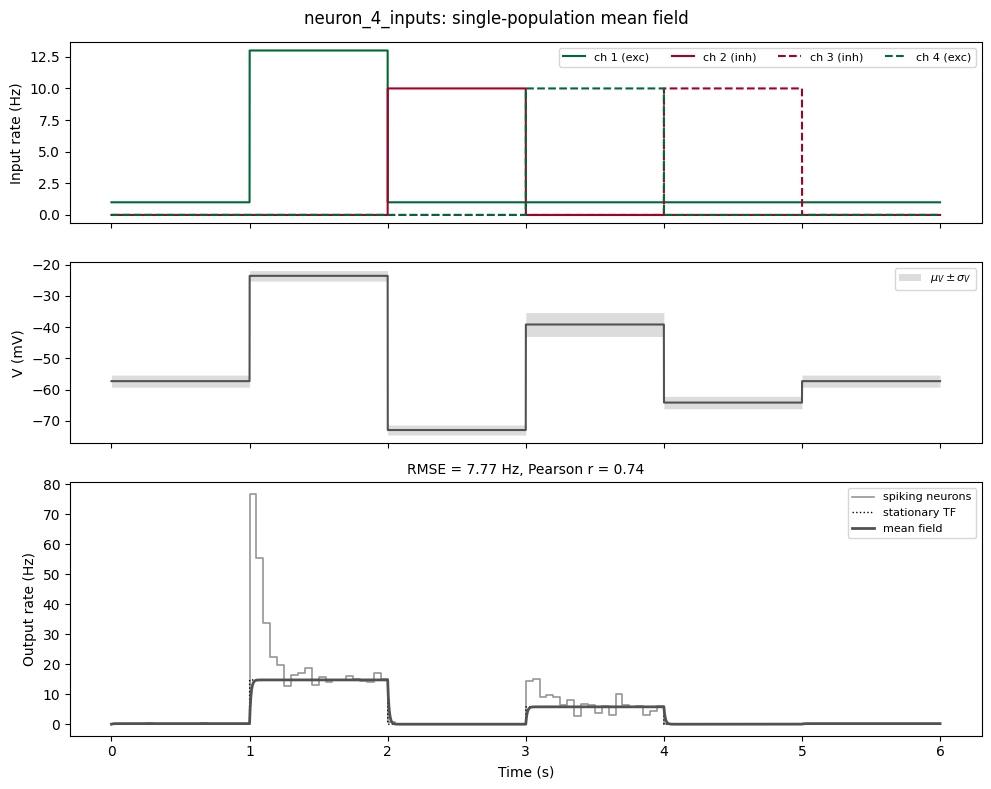

In [11]:
fig = plot_MF_single_pop(mf, driving_input, ch_info, neuron_model, nn = nn, stats = stats)
figs.append(fig)

In [12]:
if run_spiking_comparison:
    # Mean rate in each protocol epoch, skipping the first 0.5 s after each change (adaptation transient)
    edges = sorted({0.0, sim_duration} | {s[key] for ch in protocol['channels'].values()
                                          for s in ch['stimulations'] for key in ('t_start', 't_end')})
    rows = []
    for t0, t1 in zip(edges[:-1], edges[1:]):
        sel_mf = (mf['t'] >= t0 + 0.5) & (mf['t'] < t1)
        sel_nn = (nn['t'] >= t0 + 0.5) & (nn['t'] < t1)
        rows.append({'t_start (s)': t0, 't_end (s)': t1,
                     'MF (Hz)': mf['nu'][sel_mf].mean(), 'spiking (Hz)': nn['rate'][sel_nn].mean()})
    epochs = pd.DataFrame(rows).round(2)
    display(epochs)

,t_start (s),t_end (s),MF (Hz),spiking (Hz)
0,0.0,1.0,0.20,0.04
1,1.0,2.0,14.77,15.12
2,2.0,3.0,0.00,0.00
3,3.0,4.0,5.79,5.44
4,4.0,5.0,0.00,0.00
5,5.0,6.0,0.20,0.00


In [13]:
save_figs(fig_path, fig_name, figs)